#### Configuration
Read the saved 100-trial Qwen3-4B sweep; RUN regenerates it only when explicitly enabled.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / 'llm' / 'model.py').is_file())
sys.path.insert(0, str(REPO_ROOT))
import matplotlib.pyplot as plt
import numpy as np

RUN = False
MODEL_NAME, CONCEPT, PROMPT = 'Qwen/Qwen3-4B', 'football', 'Once upon a time'
SEED, RANDOM_SEED = 0, 0
DIRECTION_SAMPLES, JACOBIAN_SAMPLES, MAX_CTX, BATCH_SIZE = 200, 50, 32, 8
Q, R, QF = 0.1, 10, 0.1
TRIALS, MAX_NEW_TOKENS, JUDGE_BATCH = 100, 96, 128
TEMPERATURE, TOP_P = 0.7, 0.95
OPERATOR_NAMES = ('Identity', 'Mean Jacobian', 'Random')
MODEL_DIR = REPO_ROOT / 'artifacts' / MODEL_NAME.rsplit('/', 1)[-1].lower()
E_PATH = MODEL_DIR / '01_concept_direction_steering' / f'E_{CONCEPT}_n{DIRECTION_SAMPLES}_seed{SEED}.pt'
A_PATH = MODEL_DIR / '02_qwen3_model_ablation' / f'A_{CONCEPT}_n{JACOBIAN_SAMPLES}_ctx{MAX_CTX}_seed{SEED}.pt'

EVERY, LAMBDAS = (1, 2, 3, 4), tuple(np.arange(0.5, 4.5, 0.5))
ARTIFACTS = MODEL_DIR / '02_qwen3_model_ablation'
RESULTS_PATH = ARTIFACTS / f'ablation_{CONCEPT}.csv'

#### Model and caches
Only regeneration loads models and shared concept-direction and mean-Jacobian caches.

In [2]:
if RUN:
    import gc
    import random
    import torch
    from llm.model import load_model, blocks
    from llm.concepts import concept_direction, load_concept_prompts
    from llm.jacobian import efficient_mean_jacobian
    from llm.steering import LQRSteering, sample
    from llm.trace import trace, completion_metrics
    from llm.judge import build_judge, concept_criterion, COHERENCE

    random.seed(SEED)
    torch.manual_seed(SEED)
    tokenizer, model = load_model(MODEL_NAME)
    prompt_length = len(tokenizer(PROMPT)['input_ids'])
    layers, hidden = len(blocks(model)), model.get_input_embeddings().weight.shape[1]
    E_PATH.parent.mkdir(parents=True, exist_ok=True)
    A_PATH.parent.mkdir(parents=True, exist_ok=True)
    ARTIFACTS.mkdir(parents=True, exist_ok=True)
    if E_PATH.exists():
        E = torch.load(E_PATH, weights_only=True)
    else:
        E = concept_direction(model, tokenizer, CONCEPT, DIRECTION_SAMPLES, BATCH_SIZE)
        torch.save(E, E_PATH)
    if A_PATH.exists():
        A = torch.load(A_PATH, weights_only=True, map_location='cpu')
    else:
        random.seed(SEED + 1)
        targets, _ = load_concept_prompts(CONCEPT, JACOBIAN_SAMPLES)
        A = efficient_mean_jacobian(model, tokenizer, targets, max_ctx=MAX_CTX).cpu()
        torch.save(A, A_PATH)
    identity = torch.eye(hidden)
    noise = torch.randn(layers, hidden, hidden, generator=torch.Generator().manual_seed(RANDOM_SEED))
    scale = torch.linalg.matrix_norm(A - identity) / torch.linalg.matrix_norm(noise)
    operators = dict(zip(OPERATOR_NAMES, (identity.expand(layers, -1, -1), A,
                                         identity + scale[:, None, None] * noise)))
    del noise
    sample_kwargs = dict(max_new_tokens=MAX_NEW_TOKENS, temperature=TEMPERATURE, top_p=TOP_P)

#### Sweep
Identity, Mean Jacobian, and norm-matched Random dynamics use matched sampling seeds.

In [3]:
if RUN:
    torch.manual_seed(SEED)
    ids = sample(model, tokenizer, PROMPT, TRIALS, **sample_kwargs)
    results = [dict(every=0, operator='Unsteered', **{'lambda': 0.0}, completion=text.strip())
               for text in tokenizer.batch_decode(ids[:, prompt_length:], skip_special_tokens=True)]
    for every in EVERY:
        for name, operator in operators.items():
            controller = LQRSteering(model, operator, E, Q, R, QF, every=every)
            for i, lmbda in enumerate(LAMBDAS):
                torch.manual_seed(SEED + i)
                ids = sample(model, tokenizer, PROMPT, TRIALS, controller=controller,
                             lmbda=lmbda, **sample_kwargs)
                replay = trace(model, controller, lmbda, ids, prompt_length)
                texts = tokenizer.batch_decode(ids[:, prompt_length:], skip_special_tokens=True)
                for text, metrics in zip(texts, completion_metrics(replay)):
                    results.append(dict(every=every, operator=name, **{'lambda': lmbda},
                                        completion=text.strip(), **metrics))
                del replay
            del controller
    results = pd.DataFrame(results)

#### Results
Judge regenerated completions, or load the final saved table without model or judge loading.

In [4]:
if RUN:
    del model
    gc.collect()
    torch.cuda.empty_cache()
    judge = build_judge(batch_size=JUDGE_BATCH)
    texts = results['completion'].tolist()
    results['concept'] = judge(concept_criterion(CONCEPT), PROMPT, texts)
    results['coherent'] = judge(COHERENCE, PROMPT, texts)
    results['both'] = results['concept'] & results['coherent']
    results.to_csv(RESULTS_PATH, index=False)
    del judge
else:
    results = pd.read_csv(RESULTS_PATH)

#### Summary
Each row gives the lambda with the highest on-concept-and-coherent rate in its saved sweep.

In [5]:
selected = results[results['every'].isin(EVERY) & results['operator'].isin(OPERATOR_NAMES)
                   & results['lambda'].isin(LAMBDAS)]
groups = selected.groupby(['every', 'operator', 'lambda'])
summary = groups.agg(concept=('concept', 'mean'), coherent=('coherent', 'mean'),
                     both=('both', 'mean'), n=('concept', 'size')).reset_index()
for metric in ('concept', 'coherent'):
    summary[f'{metric}_se'] = np.sqrt(summary[metric] * (1 - summary[metric]) / summary['n'])
best = summary.loc[summary.groupby(['every', 'operator'])['both'].idxmax()]
display(best[['every', 'operator', 'lambda', 'concept', 'coherent', 'both', 'n']].round(3))

,every,operator,lambda,concept,coherent,both,n
7,1,Identity,4.0,0.93,0.81,0.77,100
12,1,Mean Jacobian,2.5,0.90,0.69,0.65,100
22,1,Random,3.5,0.97,0.76,0.76,100
31,2,Identity,4.0,0.53,0.89,0.44,100
37,2,Mean Jacobian,3.0,0.67,0.78,0.53,100
47,2,Random,4.0,0.88,0.81,0.72,100
55,3,Identity,4.0,0.26,0.95,0.26,100
63,3,Mean Jacobian,4.0,0.89,0.68,0.63,100
71,3,Random,4.0,0.57,0.86,0.48,100
79,4,Identity,4.0,0.16,0.98,0.15,100


#### Coherence versus concept
Each actuation panel shows one curve per operator with marginal binomial standard errors.

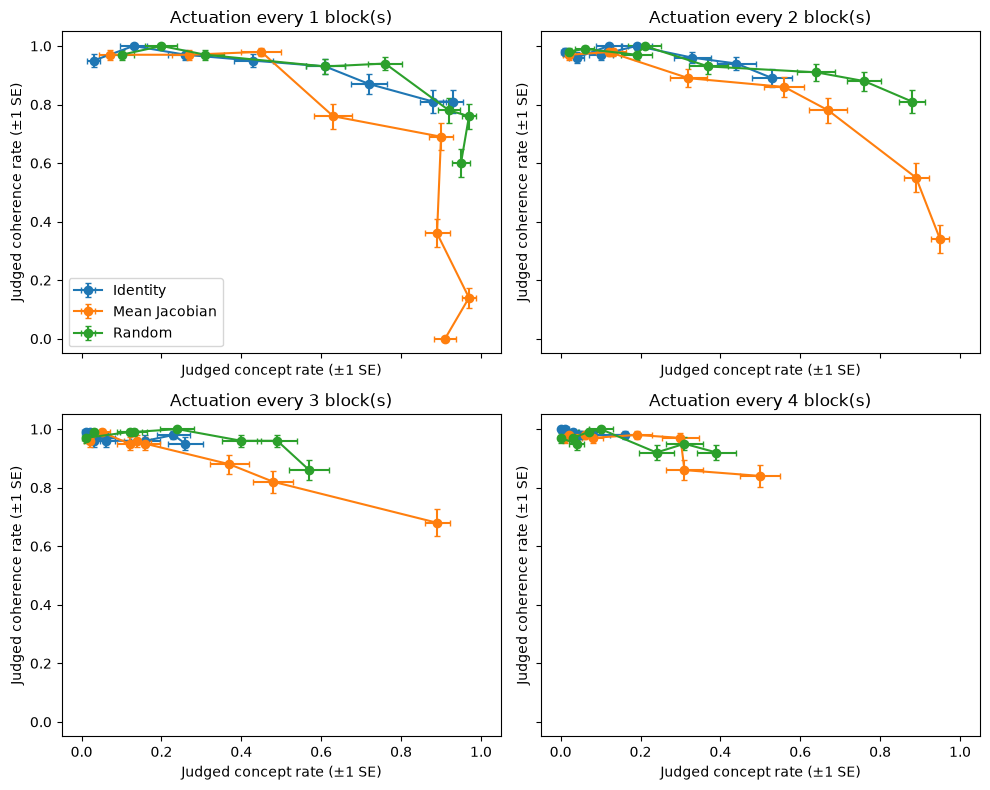

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
for ax, every in zip(axes.flat, EVERY):
    for name in OPERATOR_NAMES:
        curve = summary[(summary['every'] == every) & (summary['operator'] == name)].sort_values('lambda')
        ax.errorbar(curve['concept'], curve['coherent'], xerr=curve['concept_se'],
                    yerr=curve['coherent_se'], marker='o', capsize=2, label=name)
    ax.set(title=f'Actuation every {every} block(s)', xlabel='Judged concept rate (±1 SE)',
           ylabel='Judged coherence rate (±1 SE)', xlim=(-0.05, 1.05), ylim=(-0.05, 1.05))
axes.flat[0].legend()
fig.tight_layout()
ARTIFACTS.mkdir(parents=True, exist_ok=True)
fig.savefig(ARTIFACTS / f'ablation_{CONCEPT}.png', dpi=150)
plt.show()

#### Result
In the saved sweep, mean on-concept-and-coherent rates across the eight strengths were 0.436 / 0.298 / 0.490 for Identity / Mean Jacobian / Random at every-block actuation, versus 0.049 / 0.164 / 0.144 at every-fourth-block actuation. These sweep averages are not comparisons at matched concept strength.